In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, roc_auc_score,average_precision_score, confusion_matrix,precision_recall_curve)
import pickle, os


In [2]:
DATA_PATH = "/content/Fraud.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print(df['isFraud'].value_counts())
df.head()


Shape: (6362620, 11)
isFraud
0    6354407
1       8213
Name: count, dtype: int64


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
df['diffOrig'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['diffDest'] = df['newbalanceDest'] - df['oldbalanceDest']

df['destIsMerchant'] = df['nameDest'].astype(str).str.startswith('M').astype(int)
df['origIsMerchant'] = df['nameOrig'].astype(str).str.startswith('M').astype(int)

df['largeAmountFlag'] = (df['amount'] > 200000).astype(int)

ohe = pd.get_dummies(df['type'], prefix='type', drop_first=True)
df = pd.concat([df, ohe], axis=1)


In [4]:

df_model = df.drop(columns=['nameOrig', 'nameDest', 'type'])

num_cols = df_model.select_dtypes(include=[np.number]).columns.tolist()
df_model[num_cols] = df_model[num_cols].replace([np.inf, -np.inf], np.nan)
df_model[num_cols] = df_model[num_cols].fillna(0)


In [5]:
max_sample = 300000
if len(df_model) > max_sample:
    df_sample = df_model.groupby('isFraud', group_keys=False).apply(
        lambda x: x.sample(min(len(x), max_sample // 2), random_state=42)
    ).sample(frac=1, random_state=42).reset_index(drop=True)
else:
    df_sample = df_model.copy()

print("Sample shape:", df_sample.shape)
print(df_sample['isFraud'].value_counts())


Sample shape: (158213, 17)
isFraud
0    150000
1      8213
Name: count, dtype: int64


/tmp/ipython-input-2828873054.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df_model.groupby('isFraud', group_keys=False).apply(


In [6]:
y = df_sample['isFraud']
X = df_sample.drop(columns=['isFraud', 'isFlaggedFraud'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.3, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (110749, 15) Test: (47464, 15)


In [7]:
numeric_features = [
    'step', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'diffOrig', 'diffDest'
]

scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])


In [8]:
clf = RandomForestClassifier(
    n_estimators=150, max_depth=12,
    class_weight='balanced', random_state=42, n_jobs=-1
)

clf.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', max_depth=12, n_estimators=150,
                       n_jobs=-1, random_state=42)

In [9]:
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, digits=4))
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("PR AUC:", average_precision_score(y_test, y_proba))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0     0.9993    0.9929    0.9961     45000
           1     0.8834    0.9874    0.9325      2464

    accuracy                         0.9926     47464
   macro avg     0.9414    0.9901    0.9643     47464
weighted avg     0.9933    0.9926    0.9928     47464

ROC AUC: 0.999149183802309
PR AUC: 0.9936666245263843
Confusion matrix:
 [[44679   321]
 [   31  2433]]


In [10]:
importances = pd.Series(clf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(20)


,0
diffOrig,0.321466
oldbalanceOrg,0.152081
newbalanceOrig,0.111874
amount,0.094079
diffDest,0.062682
type_TRANSFER,0.062101
newbalanceDest,0.037784
destIsMerchant,0.035086
step,0.034509
type_PAYMENT,0.030390


In [11]:
os.makedirs('/mnt/data/model_output', exist_ok=True)

with open('/mnt/data/model_output/rf_model.pkl', 'wb') as f:
    pickle.dump(clf, f)

with open('/mnt/data/model_output/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)


In [12]:
results_df = X_test.copy()
results_df["Actual"] = y_test.values
results_df["Predicted"] = y_pred
results_df["Pred_Prob"] = y_proba

def outcome(row):
    if row["Actual"] == 1 and row["Predicted"] == 1:
        return "TP"
    elif row["Actual"] == 0 and row["Predicted"] == 0:
        return "TN"
    elif row["Actual"] == 0 and row["Predicted"] == 1:
        return "FP"
    else:
        return "FN"

results_df["Outcome"] = results_df.apply(outcome, axis=1)


In [13]:
false_alarms = results_df[results_df["Outcome"] == "FP"]

missed_frauds = results_df[results_df["Outcome"] == "FN"]

print("False Alarms (FP):", false_alarms.shape[0])
print("Missed Frauds (FN):", missed_frauds.shape[0])

false_alarms.head()
missed_frauds.head()


False Alarms (FP): 321
Missed Frauds (FN): 31


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,diffOrig,diffDest,destIsMerchant,origIsMerchant,largeAmountFlag,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,Actual,Predicted,Pred_Prob,Outcome
88736,-0.633605,0.501188,-0.063401,-0.283593,-0.296739,-0.290522,0.967674,-0.064409,0,0,1,False,False,False,True,1,0,0.476382,FN
157728,-0.293073,0.865499,0.044999,-0.283593,-0.296739,-0.139981,1.454299,0.578504,0,0,1,False,False,False,True,1,0,0.422349,FN
121392,-1.568399,-0.175844,-0.297607,-0.283593,-0.296739,-0.291697,-0.083716,-0.069425,0,0,0,True,False,False,False,1,0,0.264321,FN
55749,-1.414825,-0.283168,-0.296785,-0.283593,-0.220103,-0.195102,-0.080025,0.039301,0,0,0,True,False,False,False,1,0,0.421021,FN
44048,-1.581753,-0.285460,-0.297467,-0.283593,-0.047796,-0.039495,-0.083087,0.020799,0,0,0,True,False,False,False,1,0,0.377044,FN


In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve, auc
from xgboost import XGBClassifier


In [9]:
DATA_PATH = "/content/Fraud.csv"
df = pd.read_csv(DATA_PATH)

df['diffOrig'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['diffDest'] = df['newbalanceDest'] - df['oldbalanceDest']
df['destIsMerchant'] = df['nameDest'].astype(str).str.startswith('M').astype(int)
df['origIsMerchant'] = df['nameOrig'].astype(str).str.startswith('M').astype(int)
df['largeAmountFlag'] = (df['amount'] > 200000).astype(int)

ohe = pd.get_dummies(df['type'], prefix='type', drop_first=True)
df = pd.concat([df, ohe], axis=1)

df_model = df.drop(columns=['nameOrig', 'nameDest', 'type'])

num_cols = df_model.select_dtypes(include=[np.number]).columns.tolist()
df_model[num_cols] = df_model[num_cols].replace([np.inf, -np.inf], np.nan).fillna(0)


In [10]:
y = df_model['isFraud']
X = df_model.drop(columns=['isFraud', 'isFlaggedFraud'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Fraud ratio train:", y_train.mean(), "test:", y_test.mean())


Train: (4453834, 15) Test: (1908786, 15)
Fraud ratio train: 0.001290797995614565 test: 0.001290872837499856


In [11]:
numeric_features = [
    'step','amount','oldbalanceOrg','newbalanceOrig',
    'oldbalanceDest','newbalanceDest','diffOrig','diffDest'
]
scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])


In [12]:
scale = (len(y_train) - y_train.sum()) / y_train.sum()

clf = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)

In [13]:
y_proba = clf.predict_proba(X_test)[:,1]

print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("PR AUC:", average_precision_score(y_test, y_proba))

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
best_idx = np.argmax(recall - (1 - precision))
best_thresh = thresholds[best_idx]
print("Best threshold:", best_thresh)

y_pred_thresh = (y_proba >= best_thresh).astype(int)
print(classification_report(y_test, y_pred_thresh, digits=4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_thresh))


ROC AUC: 0.9996951503263297
PR AUC: 0.9592592420157618
Best threshold: 0.9909045
              precision    recall  f1-score   support

           0     0.9998    0.9999    0.9999   1906322
           1     0.9506    0.8677    0.9073      2464

    accuracy                         0.9998   1908786
   macro avg     0.9752    0.9338    0.9536   1908786
weighted avg     0.9998    0.9998    0.9998   1908786

Confusion Matrix:
 [[1906211     111]
 [    326    2138]]


diffOrig           0.295589
newbalanceOrig     0.195157
type_PAYMENT       0.161693
destIsMerchant     0.141689
type_TRANSFER      0.053188
amount             0.037171
largeAmountFlag    0.036521
oldbalanceOrg      0.023306
newbalanceDest     0.016169
type_CASH_OUT      0.016092
diffDest           0.010684
step               0.006703
oldbalanceDest     0.003105
type_DEBIT         0.002932
origIsMerchant     0.000000
dtype: float32


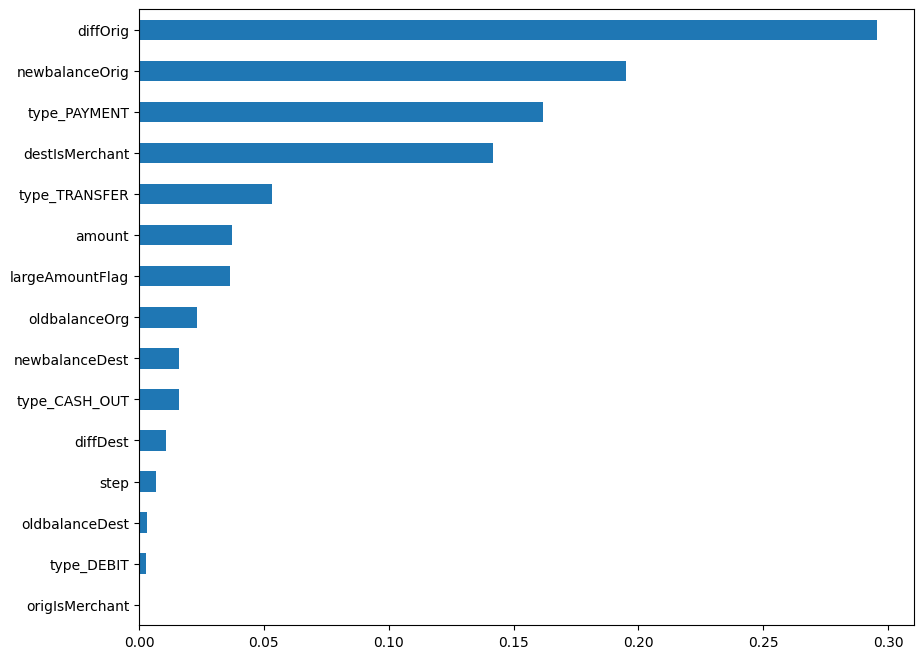

In [14]:
import matplotlib.pyplot as plt

importances = pd.Series(clf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.head(20))

# Plot
importances.head(20).plot(kind='barh', figsize=(10,8))
plt.gca().invert_yaxis()
plt.show()


In [16]:
results_df = X_test.copy()
results_df["Actual"] = y_test.values
results_df["Pred_Prob"] = y_proba
results_df["Predicted"] = y_pred_thresh

def outcome(row):
    if row["Actual"] == 1 and row["Predicted"] == 1:
        return "TP"
    elif row["Actual"] == 0 and row["Predicted"] == 0:
        return "TN"
    elif row["Actual"] == 0 and row["Predicted"] == 1:
        return "FP"
    else:
        return "FN"

results_df["Outcome"] = results_df.apply(outcome, axis=1)

flagged_transactions = results_df[results_df["Predicted"] == 1]

flagged_real = df.loc[flagged_transactions.index, [
    'step','amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest'
]].copy()

flagged_real['Pred_Prob'] = flagged_transactions['Pred_Prob'].values
flagged_real['Outcome'] = flagged_transactions['Outcome'].values

print("Number of flagged transactions:", flagged_real.shape[0])
display(flagged_real.head())

flagged_real.to_csv("/content/flagged_transactions_real_amounts.csv", index=False)
print("Flagged transactions with real amounts exported to /content/flagged_transactions_real_amounts.csv")


Number of flagged transactions: 2249


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,Pred_Prob,Outcome
2885346,228,120491.56,120491.56,0.0,0.00,0.00,0.999944,TP
1030379,60,89014.32,89014.32,0.0,0.00,0.00,0.999992,TP
5980079,408,2567602.10,2567602.10,0.0,0.00,2567602.10,0.999993,TP
1141252,131,10000000.00,10000000.00,0.0,179252.82,10179252.82,0.999968,TP
6117346,528,1016302.60,1016302.60,0.0,0.00,0.00,0.999999,TP


Flagged transactions with real amounts exported to /content/flagged_transactions_real_amounts.csv


In [17]:
tp_count = flagged_real[flagged_real['Outcome'] == 'TP'].shape[0]
fp_count = flagged_real[flagged_real['Outcome'] == 'FP'].shape[0]

print("Summary of flagged transactions (real amounts):")
print("Total flagged transactions:", flagged_real.shape[0])
print("True Positives (correctly flagged frauds):", tp_count)
print("False Positives (normal transactions flagged incorrectly):", fp_count)

top_risk = flagged_real.sort_values(by='Pred_Prob', ascending=False).head(50)
print("\nTop 50 highest-risk transactions:")
display(top_risk[['step','amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest','Pred_Prob','Outcome']])

top_risk.to_csv("/content/top_50_flagged_transactions_real_amounts.csv", index=False)
print("\nTop 50 highest-risk transactions exported to /content/top_50_flagged_transactions_real_amounts.csv")


Summary of flagged transactions (real amounts):
Total flagged transactions: 2249
True Positives (correctly flagged frauds): 2138
False Positives (normal transactions flagged incorrectly): 111

Top 50 highest-risk transactions:


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,Pred_Prob,Outcome
6286015,659,1321984.45,1321984.45,0.00,0.0,0.0,1.0,TP
6349483,695,1305754.09,1305754.09,0.00,0.0,0.0,1.0,TP
6283804,657,2333929.91,2333929.91,0.00,0.0,0.0,1.0,TP
6362362,723,1232697.94,1232697.94,0.00,0.0,0.0,1.0,TP
6351245,704,1820864.64,1820864.64,0.00,0.0,0.0,1.0,TP
6272317,621,3054359.40,3054359.40,0.00,0.0,0.0,1.0,TP
6272361,621,6038051.03,6038051.03,0.00,0.0,0.0,1.0,TP
6278030,641,2666139.51,2666139.51,0.00,0.0,0.0,1.0,TP
6264971,613,2155569.91,2155569.91,0.00,0.0,0.0,1.0,TP
6273152,631,3120690.98,3120690.98,0.00,0.0,0.0,1.0,TP



Top 50 highest-risk transactions exported to /content/top_50_flagged_transactions_real_amounts.csv
